# Loopback delay, step by step (rf-clock)

The same measurement as the M3 check (`python -m rf_clock.checks.m3_loopback`), split into one cell per step, with a plot after each one, so every intermediate result of the Python layer can be seen.

**What it does:** at an exact tick after a PPS edge, the FPGA sends a PRN burst on DAC_A and, from the same tick, records ADC_B into memory. Correlating the recording with the transmitted waveform gives the loopback delay: DAC + cables + filter + attenuator + ADC.

**Before running:**
* Cabling: **DAC_A → BPF → attenuator → ADC_B**, no antennas, no amplifier powered. **This notebook transmits** (5.8 GHz bursts on DAC_A).
* FS725 10 MHz (through the EPG1) on the reference input, PPS on J7.
* Run it in the board's own Jupyter (it runs as root, which PYNQ needs). Do not run the `rf_clock.checks` scripts at the same time: only one program may drive the overlay.

Library: rf-clock 1.3.0.8 (Haoyu Dong), API in `docs/ABI.md`.

## 0. Setup
`xrfclk` reads the board name from the `BOARD` variable when it is imported, and PYNQ needs `XILINX_XRT`; the command-line checks set both with `sudo env ...`, here they are set before the import.

In [1]:
import os
os.environ.setdefault("BOARD", "RFSoC4x2")
os.environ.setdefault("XILINX_XRT", "/usr")

%matplotlib inline
import time
import numpy as np
import matplotlib.pyplot as plt

from rf_clock.pl import PL, WaveformGenerator
from rf_clock.correlator import correlate, find_peak

# ---- measurement parameters (same defaults as the M3 check) ----
OFFSET_TICKS = 100_000      # burst at PPS + 1 ms (1 tick = 10 ns)
MARGIN_BEATS = 1250         # RX window longer than the burst by 1250 beats = 12.5 us
AMPLITUDE    = 16000.0      # DAC amplitude (of 32767 full scale)
N_REPEAT     = 10           # captures in step 8

FS        = 800e6           # complex sample rate in the FPGA (8 samples per 100 MHz tick)
SPS       = 8               # samples per chip -> 100 Mchip/s
SAMPLE_NS = 1e9 / FS        # 1.25 ns

## 1. Power-up: overlay, clocks, converters, MTS, PPS lock
`PL.open()` does every power-up step of `docs/ABI.md` §7.1. Each step is printed as it happens (the same `m:` lines as in the check logs):

* load the overlay (bitstream + hardware description),
* write the clock chips: LMK04828 from the 10 MHz, then the two LMX2594 with the VCO bands **forced from this board's config** (`/etc/rf-clock/board.json`),
* start the converter tiles and run **multi-tile sync (MTS)**, so the converter latency is the same at every power-up,
* release the PL reset and wait for the **PPS lock**.

Running this cell again is a complete restart of the timing chain.

In [2]:
steps = []
def progress(msg):
    steps.append(msg)
    print("m:", msg, flush=True)

pl = PL.open(progress=progress)

mts = pl.rfdc.mts
print()
print("board        :", pl.board.serial, f"({pl.board.config.label if pl.board.config else 'no config'})")
for side, v in pl.board.lmx_vco.items():
    print(f"LMX2594 {side}: band {v.band}, locked {v.locked}")
print(f"DAC MTS      : ok={mts.dac.ok}, {mts.dac.status}")
print(f"ADC MTS      : ok={mts.adc.ok}, {mts.adc.status}")
for kind, s in mts.mixers.items():
    print(f"{kind} mixer    : NCO {s.get('Freq'):.1f} MHz, mode {s.get('MixerMode')}")

m: rf-clock 1.3.0.8; overlay manifest 1.3.0.0 matches
m: board 16908308541004718c70a080a0800003 (8873292600AB): board config matches
m: boot state: degraded
m: Overlay(/usr/local/share/pynq-venv/lib/python3.10/site-packages/rf_clock/overlay/rf_clock.bit) start


m: Overlay loaded
m: xrfclk start
m: xrfclk wrote LMK04828_100.0 + LMX2594_480.0
m: ADC LMX2594 VCO1 band 124 forced (calibration chose 114), DACISET 272, locked
m: DAC LMX2594 VCO1 band 126 forced (calibration chose 114), DACISET 259, locked
m: pl_resetn0 pulse
m: RFDC tile start-up and MTS
m: DAC MTS OK (ref tile 0; tile 0: latency 1896 offset 8, tile 2: latency 1896 offset 8)
m: ADC MTS OK (ref tile 0; tile 0: latency 1296 offset 10, tile 2: latency 1296 offset 10)

board        : 16908308541004718c70a080a0800003 (8873292600AB)
LMX2594 adc: band 124, locked True
LMX2594 dac: band 126, locked True
DAC MTS      : ok=True, 0
ADC MTS      : ok=True, 0
DAC mixer    : NCO -1000.0 MHz, mode 2
ADC mixer    : NCO -1000.0 MHz, mode 3


## 2. The time base: ticks and PPS
The FPGA counts a 100 MHz **tick** derived from the 10 MHz and records the tick of every PPS edge. `wait_next_pps()` returns (PPS count, tick of that edge). Two consecutive edges must be exactly 100 000 000 ticks apart (what M1 checks).

In [3]:
n1, t1 = pl.ctrl.wait_next_pps()
n2, t2 = pl.ctrl.wait_next_pps()
print(f"PPS {n1} at tick {t1}")
print(f"PPS {n2} at tick {t2}")
print(f"ticks between them: {t2 - t1}  (expected 100000000)")

PPS 6 at tick 561599088
PPS 7 at tick 661599088
ticks between them: 100000000  (expected 100000000)


## 3. The transmit waveform
Generated on the ARM by `WaveformGenerator`, as in the simulation notebook: **chips** from an LFSR, **BPSK** (±1), **RRC** filtering with β = 0.25 at 8 samples per chip, then quantised to 16-bit DAC values. BPSK is real, so the waveform goes on I and Q is zero.

The burst is `chip_count` chips plus the RRC tails at both ends. It is then packed into 256-bit **beats** of 8 complex samples, one beat per tick, which is the format of the FPGA's transmit buffer.

chips          : 4096 at 100 Mchip/s (40.96 us)
RRC            : beta 0.25, span 10 chips, 81 taps
burst          : 32841 samples = 41.051 us (73 tail samples)
beats          : 4106 (8 samples each)
peak / rms     : 15680 / 8912 (DAC full scale 32767)


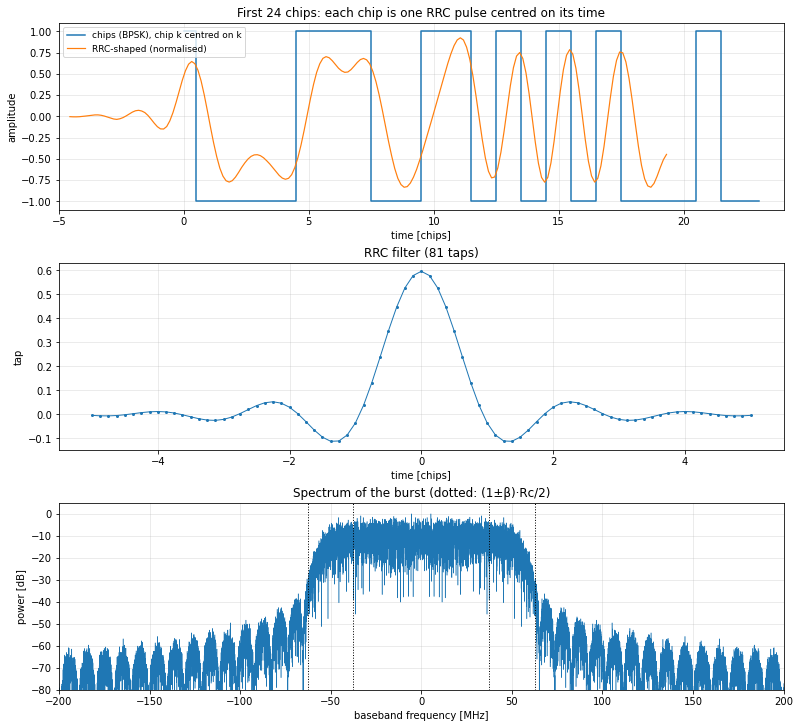

In [4]:
gen   = WaveformGenerator(amplitude=AMPLITUDE)
chips = gen.chips()                         # 0/1 or +-1 chips from the LFSR
ref   = gen.generate().astype(np.float64)   # the RRC-shaped burst (I samples), also the correlation reference
beats = gen.generate_beats()                # packed for the TX buffer

print(f"chips          : {gen.chip_count} at {FS / SPS / 1e6:.0f} Mchip/s ({gen.chip_count * SPS / FS * 1e6:.2f} us)")
print(f"RRC            : beta {gen.beta}, span {gen.span_chips} chips, {gen.tap_count} taps")
print(f"burst          : {ref.size} samples = {ref.size / FS * 1e6:.3f} us ({gen.tail_samples} tail samples)")
print(f"beats          : {len(beats)} (8 samples each)")
print(f"peak / rms     : {np.abs(ref).max():.0f} / {np.sqrt(np.mean(ref ** 2)):.0f} (DAC full scale 32767)")

n_show = 24
fig, ax = plt.subplots(3, 1, figsize=(11, 10), layout="constrained")
c = np.asarray(chips[:n_show], dtype=float)
c = np.where(c > 0.5, 1.0, -1.0) if set(np.unique(c)) <= {0.0, 1.0} else np.sign(c)
ax[0].step(np.arange(n_show), c, where="mid", lw=1.5, label="chips (BPSK), chip k centred on k")
seg = ref[: n_show * SPS]
ax[0].plot(np.arange(seg.size) / SPS - (gen.tail_samples / 2) / SPS, seg / np.abs(ref).max(), lw=1.2,
           label="RRC-shaped (normalised)")
ax[0].set(xlabel="time [chips]", ylabel="amplitude", title=f"First {n_show} chips: each chip is one RRC pulse centred on its time", xlim=(-gen.span_chips / 2, n_show))
ax[0].legend(fontsize=9); ax[0].grid(alpha=0.3)
ax[1].plot((np.arange(len(gen.coeffs)) - (len(gen.coeffs) - 1) / 2) / SPS, gen.coeffs, ".-", ms=4, lw=1)
ax[1].set(xlabel="time [chips]", ylabel="tap", title=f"RRC filter ({gen.tap_count} taps)"); ax[1].grid(alpha=0.3)
f = np.fft.fftshift(np.fft.fftfreq(ref.size, 1 / FS))
P = np.fft.fftshift(np.abs(np.fft.fft(ref)) ** 2)
ax[2].plot(f / 1e6, 10 * np.log10(P / P.max() + 1e-15), lw=0.5)
for e in ((1 - gen.beta) * 50, (1 + gen.beta) * 50):
    for s in (-1, 1):
        ax[2].axvline(s * e, color="k", ls=":", lw=1)
ax[2].set(xlabel="baseband frequency [MHz]", ylabel="power [dB]", title="Spectrum of the burst (dotted: (1±β)·Rc/2)",
          xlim=(-200, 200), ylim=(-80, 5)); ax[2].grid(alpha=0.3)

## 4. Load the transmit buffer
The beats go into the FPGA's on-chip transmit buffer (UltraRAM). Nothing is sent yet: the burst only starts when it is armed for a tick (step 5).

In [5]:
pl.tx_buffer.write_beats(beats)
rx_beats = len(beats) + MARGIN_BEATS
print(f"{len(beats)} beats in the TX buffer; RX window will be {rx_beats} beats = {rx_beats * SPS / FS * 1e6:.2f} us")

4106 beats in the TX buffer; RX window will be 5356 beats = 53.56 us


## 5. Schedule the burst and the capture at the same tick
1. Wait for a PPS edge and take its tick; the target is **the next PPS + `OFFSET_TICKS`** (1 ms after it), far enough ahead that the commands reach the FPGA in time.
2. `rx_dma.prepare`: set up the DMA that will write the capture into DDR memory.
3. `arm_tx(target)` and `arm_rx(target)`: the FPGA starts both **at the target tick**.
4. `wait_tx` / `wait_rx` return the ticks at which they actually started (`TX_ACTUAL`, `RX_ACTUAL`); both must equal the target.
5. `rx_dma.wait`: the captured samples.

Because the capture starts on the same tick as the burst, the position of the burst inside the capture **is** the delay through the loop.

In [6]:
def capture_once():
    _, pps = pl.ctrl.wait_next_pps()
    target = pps + 100_000_000 + OFFSET_TICKS        # next PPS + 1 ms
    pl.rx_dma.prepare(rx_beats)                      # DMA ready before the RX doorbell
    pl.ctrl.arm_tx(target, len(beats))
    pl.ctrl.arm_rx(target, rx_beats)
    tx_actual = pl.ctrl.wait_tx(timeout=2.5)
    window = pl.ctrl.wait_rx(timeout=2.5)
    data = pl.rx_dma.wait(window.beats)
    return pps, target, tx_actual, window, np.array(data.samples)   # copy: the buffer is reused

pps, target, tx_actual, window, rx = capture_once()
print(f"PPS tick          : {pps}")
print(f"target tick       : {target}  (= next PPS + {OFFSET_TICKS})")
print(f"TX_ACTUAL - target: {tx_actual - target}")
print(f"RX_ACTUAL - target: {window.actual - target}")
print(f"captured          : {window.beats} beats = {rx.size} complex samples ({rx.size / FS * 1e6:.2f} us)")

PPS tick          : 1161599088
target tick       : 1261699088  (= next PPS + 100000)
TX_ACTUAL - target: 0
RX_ACTUAL - target: 0
captured          : 5356 beats = 42848 complex samples (53.56 us)


## 6. The raw capture
The ADC samples ADC_B at 4.8 GS/s; the 5.8 GHz burst lands in its third Nyquist zone at 1.0 GHz, and the ADC's NCO (−1000 MHz) brings it to 0 Hz. After decimation the FPGA records **complex samples at 800 MS/s**: I and Q.

* Top: the whole window. The burst appears after the loopback delay and lasts as long as the transmitted burst.
* Middle: zoom on the start of the burst. The carrier phase is arbitrary, so the signal is split between I and Q.
* Bottom: spectrum of the capture: the same RRC shape as in step 3, plus the noise floor.

|rx| peak 242, rms over the window 115.1


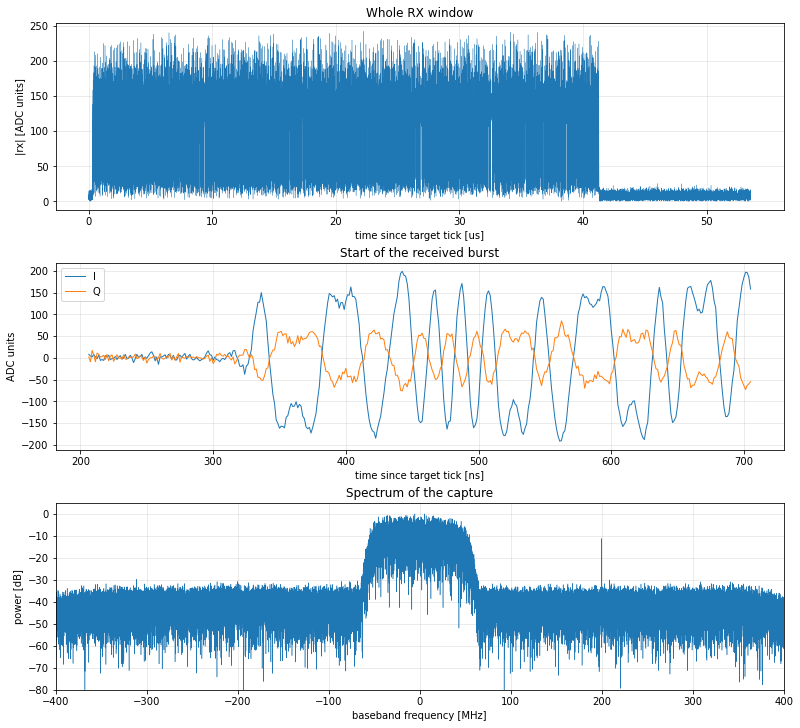

In [7]:
t_us = np.arange(rx.size) / FS * 1e6
fig, ax = plt.subplots(3, 1, figsize=(11, 10), layout="constrained")
ax[0].plot(t_us, np.abs(rx), lw=0.3)
ax[0].set(xlabel="time since target tick [us]", ylabel="|rx| [ADC units]", title="Whole RX window"); ax[0].grid(alpha=0.3)
i0 = max(int(np.argmax(np.abs(rx) > 0.3 * np.abs(rx).max())) - 100, 0)
z = slice(i0, i0 + 400)
ax[1].plot(t_us[z] * 1e3, rx.real[z], lw=1, label="I")
ax[1].plot(t_us[z] * 1e3, rx.imag[z], lw=1, label="Q")
ax[1].set(xlabel="time since target tick [ns]", ylabel="ADC units", title="Start of the received burst"); ax[1].legend(); ax[1].grid(alpha=0.3)
fr = np.fft.fftshift(np.fft.fftfreq(rx.size, 1 / FS))
Pr = np.fft.fftshift(np.abs(np.fft.fft(rx)) ** 2)
ax[2].plot(fr / 1e6, 10 * np.log10(Pr / Pr.max() + 1e-15), lw=0.5)
ax[2].set(xlabel="baseband frequency [MHz]", ylabel="power [dB]", title="Spectrum of the capture", xlim=(-400, 400), ylim=(-80, 5))
ax[2].grid(alpha=0.3)
print(f"|rx| peak {np.abs(rx).max():.0f}, rms over the window {np.sqrt(np.mean(np.abs(rx) ** 2)):.1f}")

## 7. Correlation: the delay
`correlate(rx, ref)` slides the transmitted burst along the capture and computes, for every shift $k$,
$$
c[k] = \sum_n rx[k+n]\, ref[n]^*
$$
(with FFTs). `find_peak` takes the largest $|c|$, refines its position between samples with a parabola through the peak and its two neighbours, and reports the peak-to-sidelobe ratio (PSL) and the phase.

The delay in samples is the peak position (plus `RX_ACTUAL − TX_ACTUAL`, which is 0 here); × 1.25 ns gives nanoseconds. Its phase is the carrier phase of the loop.

delay      : 229.668 samples = 287.085 ns
PSL        : 22.2 dB
phase      : -0.343 rad


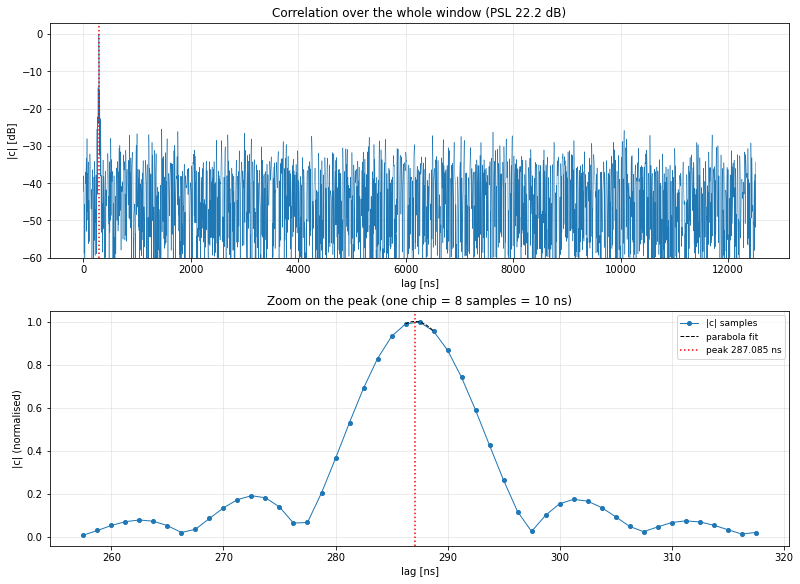

In [8]:
corr = correlate(rx, ref)
peak = find_peak(corr)
delay = peak.index + (window.actual - tx_actual) * SPS
psl_db = 20 * np.log10(peak.peak_to_sidelobe)
print(f"delay      : {delay:.3f} samples = {delay * SAMPLE_NS:.3f} ns")
print(f"PSL        : {psl_db:.1f} dB")
print(f"phase      : {peak.phase:.3f} rad")

mag = np.abs(corr) / np.abs(corr).max()
k = peak.integer_index
fig, ax = plt.subplots(2, 1, figsize=(11, 8), layout="constrained")
ax[0].plot(np.arange(mag.size) * SAMPLE_NS, 20 * np.log10(mag + 1e-9), lw=0.5)
ax[0].axvline(delay * SAMPLE_NS, color="r", ls=":", lw=1.5)
ax[0].set(xlabel="lag [ns]", ylabel="|c| [dB]", title=f"Correlation over the whole window (PSL {psl_db:.1f} dB)", ylim=(-60, 3))
ax[0].grid(alpha=0.3)
w = slice(max(k - 24, 0), k + 25)
lags = np.arange(mag.size)[w]
ax[1].plot(lags * SAMPLE_NS, mag[w], "o-", ms=4, lw=1, label="|c| samples")
a, b, cc = mag[k - 1], mag[k], mag[k + 1]                      # parabola through the three top points
xs = np.linspace(-1, 1, 101)
ax[1].plot((k + xs) * SAMPLE_NS, b + 0.5 * (cc - a) * xs + 0.5 * (a - 2 * b + cc) * xs ** 2, "k--", lw=1, label="parabola fit")
ax[1].axvline(delay * SAMPLE_NS, color="r", ls=":", lw=1.5, label=f"peak {delay * SAMPLE_NS:.3f} ns")
ax[1].set(xlabel="lag [ns]", ylabel="|c| (normalised)", title="Zoom on the peak (one chip = 8 samples = 10 ns)")
ax[1].legend(fontsize=9); ax[1].grid(alpha=0.3)

## 8. Repeat: how stable is the delay?
`N_REPEAT` captures, one per second, as in M3. The spread of the delay is the precision of one measurement.

 0  delay  287.0838 ns   PSL  22.2 dB   phase -0.339 rad
 1  delay  287.0866 ns   PSL  22.2 dB   phase -0.337 rad
 2  delay  287.0839 ns   PSL  22.2 dB   phase -0.335 rad
 3  delay  287.0844 ns   PSL  22.2 dB   phase -0.338 rad
 4  delay  287.0830 ns   PSL  22.2 dB   phase -0.342 rad
 5  delay  287.0834 ns   PSL  22.3 dB   phase -0.335 rad
 6  delay  287.0833 ns   PSL  22.2 dB   phase -0.334 rad
 7  delay  287.0845 ns   PSL  22.2 dB   phase -0.330 rad
 8  delay  287.0811 ns   PSL  22.2 dB   phase -0.339 rad
 9  delay  287.0835 ns   PSL  22.3 dB   phase -0.342 rad

mean 287.0838 ns, standard deviation 1.39 ps over 10 captures


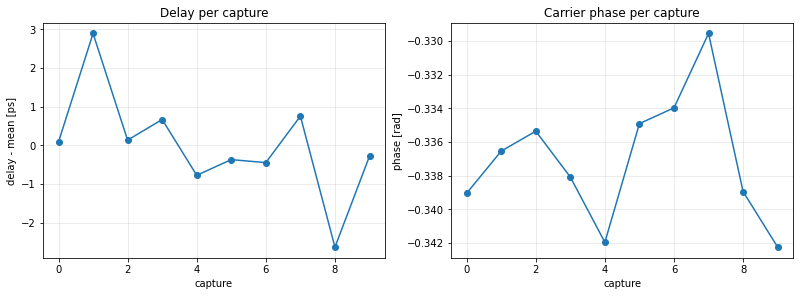

In [9]:
delays, psls, phases = [], [], []
for n in range(N_REPEAT):
    _, _, txa, win, x = capture_once()
    p = find_peak(correlate(x, ref))
    d = p.index + (win.actual - txa) * SPS
    delays.append(d); psls.append(20 * np.log10(p.peak_to_sidelobe)); phases.append(p.phase)
    print(f"{n:2d}  delay {d * SAMPLE_NS:9.4f} ns   PSL {psls[-1]:5.1f} dB   phase {p.phase:6.3f} rad", flush=True)

d_ns = np.array(delays) * SAMPLE_NS
print(f"\nmean {d_ns.mean():.4f} ns, standard deviation {d_ns.std(ddof=1) * 1e3:.2f} ps over {d_ns.size} captures")
fig, ax = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
ax[0].plot((d_ns - d_ns.mean()) * 1e3, "o-")
ax[0].set(xlabel="capture", ylabel="delay - mean [ps]", title="Delay per capture"); ax[0].grid(alpha=0.3)
ax[1].plot(phases, "o-")
ax[1].set(xlabel="capture", ylabel="phase [rad]", title="Carrier phase per capture"); ax[1].grid(alpha=0.3)

## 9. Save

In [10]:
stamp = time.strftime("%Y%m%d_%H%M%S")
path = f"loopback_{stamp}.npz"
np.savez(path, rx=rx, ref=ref, corr=corr, delays_samples=np.array(delays), psl_db=np.array(psls),
         phases=np.array(phases), target=target, tx_actual=tx_actual, rx_actual=window.actual)
print("saved", path)

saved loopback_20261023_193735.npz


The DAC only outputs during an armed burst, so nothing is transmitting after the last cell. Running step 1 again restarts the whole timing chain (clocks, MTS), which is how the delay can be compared across restarts.